# 29 · Account types, topic clusters, author recommendation, brand communities (E66-E69)

All labels are built locally from the data (author name vs brand name, text embeddings, shared authors). Outputs carry labels and counts only, never author names or URLs.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 250, "display.max_columns", 30, "display.max_colwidth", 70)
import extra_models as em, eda_utils as eu, history as H, context_text as ct, account_clusters as ac

In [2]:
f, meta = em.load(ROOT); raw_all = eu.load(ROOT); raw = raw_all.loc[f.index]
E = ct.embeddings(ROOT, ROOT / "data" / "processed" / "embeddings_e5_cache.pkl")
labels = pd.read_csv(ROOT / "data" / "processed" / "mention_labels.csv", dtype={"mention_id": str}).set_index("mention_id").type
pred = ac.oof(f, meta); print(len(f), np.abs(pred - meta.y).groupby(meta.platform).mean().round(3).to_dict())

6735 {'tiktok': 0.273, 'twitter': 0.466, 'youtube': 0.456}


## E66 · Account type from the author name
Official brand account = the author name or handle is the brand name, optionally with a country or 'official' suffix. Brand in the name = the brand name appears inside a longer name (local branch, dealer, fan or a personal handle). News / media = media words in the name.

In [3]:
share, K, Tt, D = ac.accounts(raw_all, f, meta, pred)
display(share.round(3)); display(K.round(3)); display(Tt.round(3))

col_0,official brand account,"brand in the name (branch, dealer, fan)",news / media,other
platform,,,,
facebook,0.050,0.029,0.032,0.889
instagram,0.004,0.007,0.004,0.985
tiktok,0.003,0.038,0.012,0.947
twitter,0.002,0.004,0.016,0.978
youtube,0.012,0.026,0.070,0.893


,platform,kind,posts,median_views,median_views_per_follower,bias,MAE
0,tiktok,"brand in the name (branch, dealer, fan)",95.0,829.000,2.203,-0.092,0.347
1,tiktok,news / media,30.0,687.251,0.229,-0.028,0.226
2,tiktok,official brand account,7.0,3819.000,0.063,-0.363,0.389
3,tiktok,other,2359.0,722.000,0.600,-0.016,0.271
4,twitter,"brand in the name (branch, dealer, fan)",6.0,43.715,0.119,-0.217,0.415
5,twitter,news / media,31.0,74.000,0.023,-0.274,0.426
6,twitter,official brand account,4.0,20.640,0.003,0.742,0.965
7,twitter,other,1762.0,27.000,0.065,-0.036,0.466
8,youtube,"brand in the name (branch, dealer, fan)",64.0,773.345,0.018,-0.204,0.568
9,youtube,news / media,170.0,376.996,0.003,-0.064,0.484


,platform,tier,posts,median_views,median_views_per_follower,bias,MAE
0,tiktok,100k-1M,138.0,9787.822,0.046,-0.058,0.291
1,tiktok,10k-100k,443.0,2161.000,0.089,-0.043,0.328
2,tiktok,1k-10k,812.0,690.000,0.281,-0.031,0.255
3,tiktok,< 1k,1063.0,428.000,3.713,0.005,0.262
4,tiktok,> 1M,28.0,42193.463,0.017,-0.094,0.265
5,tiktok,followers unknown,7.0,294.000,NaN,0.025,0.265
6,twitter,100k-1M,42.0,863.609,0.003,-0.156,0.674
7,twitter,10k-100k,127.0,239.000,0.010,-0.043,0.461
8,twitter,1k-10k,491.0,49.000,0.018,-0.006,0.408
9,twitter,< 1k,1106.0,17.000,0.182,-0.050,0.480


In [4]:
P66 = ac.kind_gain(f, meta, ac.account_kind(raw)); S66 = H.summarise(P66)
G66 = pd.DataFrame([{"platform": p, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P66, p, "final model", "final model + account kind")))} for p in ac.PLATS])
display(S66.round(3)); G66.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,final model,2491,0.273,0.263,0.285,-0.020
1,tiktok,final model + account kind,2491,0.272,0.261,0.285,-0.019
2,youtube,final model,2441,0.456,0.434,0.480,-0.039
3,youtube,final model + account kind,2441,0.456,0.435,0.479,-0.040
4,twitter,final model,1803,0.466,0.446,0.489,-0.039
5,twitter,final model + account kind,1803,0.468,0.448,0.490,-0.040


,platform,gain,CI low,CI high
0,tiktok,0.001,-0.001,0.003
1,youtube,-0.000,-0.004,0.003
2,twitter,-0.001,-0.003,0.001


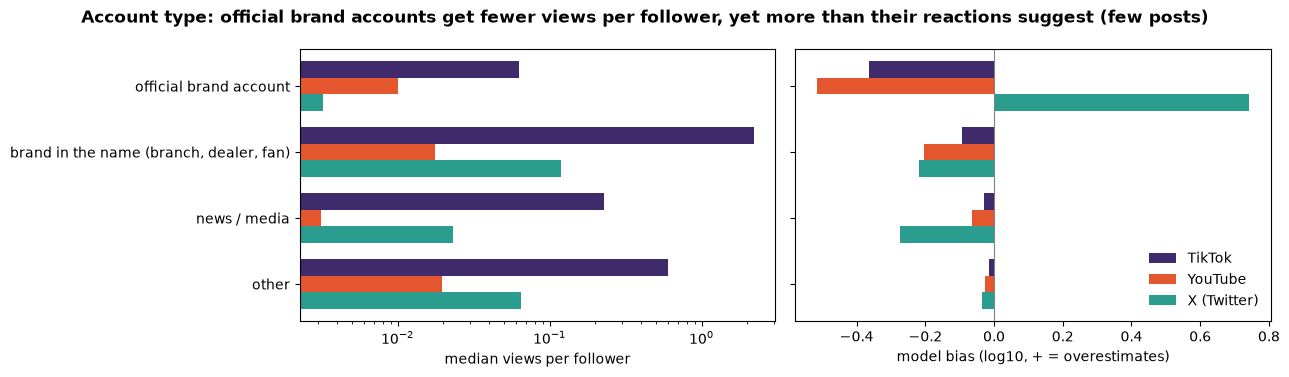

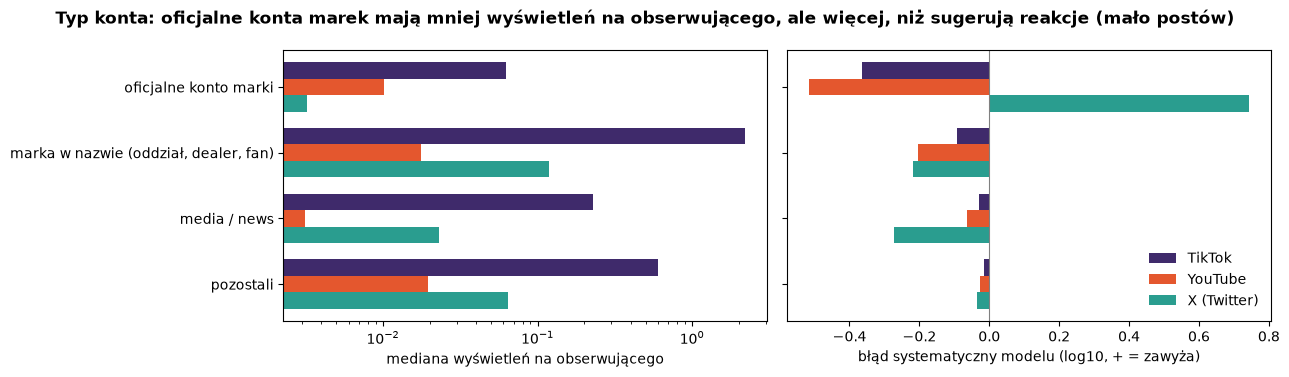

In [5]:
ac.plot_kinds(K, ROOT / "figures" / "account_kind_en.png", "en"); ac.plot_kinds(K, ROOT / "figures" / "account_kind_pl.png", "pl")

## E67 · Topic clusters
k-means (k = 16) on the e5 embeddings of all 12,500 posts; words = class-based TF-IDF. Bias = mean (predicted − true) log10 views of the final model on the cluster's TikTok / YouTube / X posts.

In [6]:
cl, words = ac.clusters(E, raw_all); T67, nmi, V = ac.cluster_table(cl, words, raw_all, meta, pred, labels)
print({k: round(v, 3) for k, v in nmi.items()}); T67.round(3)

{'brand': 0.299, 'platform': 0.202, 'type': 0.13}


,cluster,posts,brands,promo,spam,main platform,posts with views,median views,bias (pred - true),words
0,0,1040,195,0.665,0.241,YouTube 29%,591,430.000,-0.011,"mềm, phần, bạn, nissan, lyft, dental"
1,1,691,161,0.398,0.279,YouTube 42%,564,285.307,-0.089,"radar, hang, iphone, intel, asus, cpu"
2,2,1148,225,0.420,0.070,TikTok 56%,823,608.000,-0.012,"village, animation, che, skincare, shorts, mollie"
3,3,901,68,0.838,0.129,Instagram 47%,133,178.000,0.048,"hiring, hogy, campus, batch, egy, hashtags"
4,4,271,4,0.166,0.037,Instagram 94%,5,176.000,-0.458,"jag, och, att, det, för, har"
5,5,565,28,0.765,0.159,Instagram 46%,39,301.000,-0.095,"และ, der, une, les, auf, broker"
6,6,1048,255,0.093,0.048,X (Twitter) 48%,834,113.996,0.021,"cbs, panera, caesars, costco, doctor, coors"
7,7,280,2,0.821,0.018,Instagram 49%,13,833.000,-0.407,"telefon, moto, smartfon, telefonu, pamięć, razr"
8,8,540,205,0.067,0.050,X (Twitter) 77%,389,39.000,0.053,"ace, johns, hardware, papa, pringles, subaru"
9,9,1184,226,0.160,0.274,TikTok 54%,775,753.000,-0.035,"sri, gill, thenorthface, fypシ, foryoupage, vivo"


In [7]:
B67 = V.groupby(["cluster", "platform"]).e.agg(["mean", "size"]).query("size >= 40")["mean"].unstack().round(3); B67

platform,tiktok,twitter,youtube
cluster,,,
0,-0.051,0.288,-0.020
1,-0.152,-0.168,-0.015
2,-0.001,0.120,-0.147
3,0.059,NaN,-0.015
6,0.036,0.004,0.034
8,0.116,0.042,NaN
9,-0.008,-0.104,-0.194
10,0.093,-0.099,0.018
11,-0.022,-0.100,-0.039


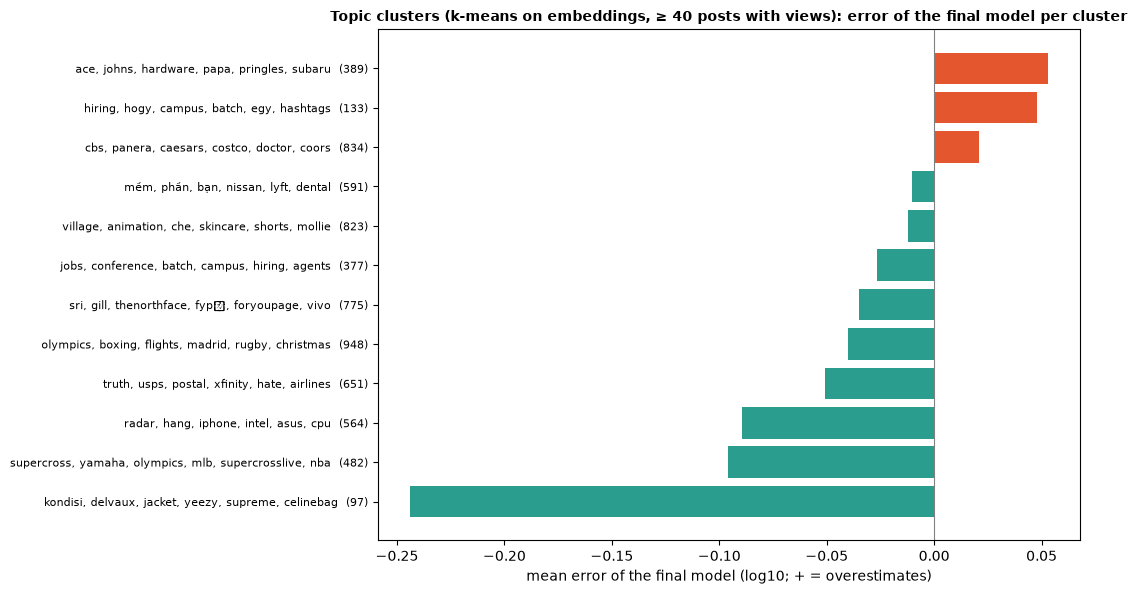

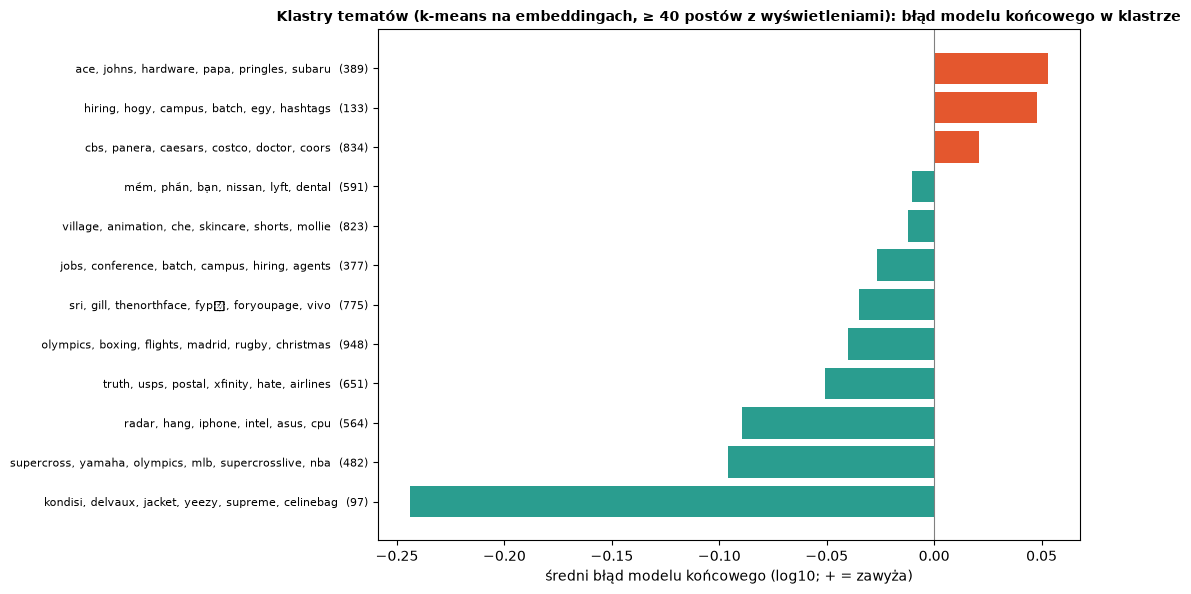

In [8]:
ac.plot_clusters(T67, ROOT / "figures" / "topic_clusters_en.png", "en"); ac.plot_clusters(T67, ROOT / "figures" / "topic_clusters_pl.png", "pl")

## E68 · Do authors who over-deliver keep over-delivering?
Over-performance = true − predicted log10 views (final model, out of fold). Authors with ≥ 2 posts with views on the platform, in time order: first post vs mean of the later ones. Bootstrap over authors.

In [9]:
A68 = ac.author_persistence(raw, meta, pred); A68.round(3)

,platform,authors,later posts,rho over-performance,rho low,rho high,top third - bottom third (log10),diff low,diff high,top vs bottom (×),rho views per follower,vpf low,vpf high
0,tiktok,61,80,0.677,0.485,0.820,0.610,0.375,0.905,4.076,0.823,0.677,0.916
1,youtube,255,400,0.691,0.607,0.763,0.858,0.681,1.041,7.203,0.801,0.732,0.853
2,twitter,83,145,0.704,0.559,0.814,0.938,0.639,1.200,8.672,0.904,0.849,0.940


In [10]:
R68 = ac.author_robustness(raw, meta, pred); R68.round(3)

,platform,later posts used,authors,rho,low,high
0,tiktok,all later posts,61,0.677,0.485,0.820
1,tiktok,later posts with new text and URL,47,0.699,0.484,0.840
2,tiktok,later posts about another brand,9,NaN,NaN,NaN
3,youtube,all later posts,255,0.691,0.603,0.763
4,youtube,later posts with new text and URL,235,0.670,0.561,0.750
5,youtube,later posts about another brand,74,0.410,0.187,0.612
6,twitter,all later posts,83,0.704,0.549,0.820
7,twitter,later posts with new text and URL,62,0.660,0.491,0.792
8,twitter,later posts about another brand,13,NaN,NaN,NaN


Use case: the author's earlier posts and their true views are known (Brand24 sees past posts). Correction = shrunk mean over-performance of the author's earlier posts; shrinkage chosen on other brand folds.

In [11]:
P68 = ac.author_history_gain(raw, meta, pred); rows = []
for (p, k), q in P68.groupby(["platform", "posts"], sort=False):
    rows.append({"platform": p, "earlier posts": k, "posts": len(q) // 2, "MAE final": float((q[q.model == "final model"].pred - q[q.model == "final model"].y).abs().mean()), **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(q, p, "final model", "final model + author history")))})
G68 = pd.DataFrame(rows); G68.round(3)

,platform,earlier posts,posts,MAE final,gain,CI low,CI high
0,tiktok,earlier posts of the author (all),80,0.356,0.124,0.065,0.188
1,tiktok,earlier posts of the author (no repeats),63,0.373,0.116,0.051,0.188
2,youtube,earlier posts of the author (all),400,0.496,0.165,0.111,0.222
3,youtube,earlier posts of the author (no repeats),379,0.495,0.157,0.106,0.216
4,twitter,earlier posts of the author (all),145,0.537,0.140,0.074,0.209
5,twitter,earlier posts of the author (no repeats),112,0.528,0.098,0.027,0.161


## E69 · Brand communities and cold start
Brands linked by shared authors (any platform) and by text similarity (5 nearest brands by mean embedding); Louvain. Cold start: does the mean over-performance of a brand's 5 most similar brands (by text) predict its own?

In [12]:
G, Sim = ac.brand_graph(raw_all, E); lab, T69, info = ac.communities(G, raw_all, None)
v = pd.DataFrame({"community": meta.brand.map(lab), "y": meta.y, "e": pred - meta.y})
T69["posts with views"] = v.groupby("community").size(); T69["median views"] = v.groupby("community").y.median().map(lambda s: 10 ** s); T69["bias (pred - true)"] = v.groupby("community").e.mean()
print(info); T69.round(3)

{'edges': 2029, 'edges with shared authors': 539, 'communities': 9, 'modularity': 0.5027031451525458}


,community,brands,posts,example brands,words,posts with views,median views,bias (pred - true)
0,0,68,3594,"AIG, Ace Hardware, Adidas, Amazon, Amazon Shipping, Authentic Bran...","sprawdź, przez, telefon, yamaha, moto, fridge",1339,382.000,-0.033
1,1,61,1155,"AB InBev, Ahold Delhaize, Albertsons Companies, Aldi, Applebee's, ...","promo, kfc, chipotle, pizza, papa, johns",1002,310.998,0.003
2,2,55,1373,"AAA, AMD, Acer, Amazon Prime Video, Apple, Asus","hang, village, animation, wwe, coca, cola",1265,418.000,-0.058
3,3,39,832,"Aetna, Airbnb, Alamo, Allegiant, American, American Eagle Outfitters","subway, boeing, postal, eagle, usps, airlines",767,333.000,-0.034
4,4,39,1493,"Alaska, Aon, Apple TV+, Burger King, Burlington, Centene","lyft, uber, tel, gig, doordash, beat",879,203.000,-0.016
5,5,30,2887,"Accenture, Acronis, Adobe, Anydesk, Autodesk, Avanza","olympics, boxing, madrid, rugby, flights, christmas",398,192.499,-0.009
6,6,25,638,"Acura, Advance Auto Parts, Audi, AutoZone, BMW, Buick","radar, nissan, jeep, rear, chevrolet, chrysler",594,402.000,-0.037
7,7,16,215,"AT&T, AT&T Internet, Boost Mobile, Breezeline, CenturyLink, Consum...","iphone, mint, xfinity, starlink, air, satellite",199,188.000,-0.117
8,8,15,313,"BMO, Bank of America, Barclays, Capital One, Citizens Bank, Fifth ...","bmo, truist, residents, citizens, banking, fargo",292,253.000,-0.045


In [13]:
C69 = ac.cold_start(Sim, meta, pred); C69.round(3)

,platform,brands (>= 5 posts),rho with similar brands,low,high,sd of brand over-performance
0,tiktok,238,0.270,0.138,0.389,0.161
1,youtube,213,0.016,-0.123,0.142,0.306
2,twitter,189,0.124,-0.030,0.258,0.282


## Takeaways
See `docs/en/experiments.md` (E66-E69). Numbers: `data/processed/accounts_clusters_numbers.json`.

In [14]:
json.dump({"kind_share": share.reset_index().to_dict("records"), "kind": K.to_dict("records"), "tier": Tt.to_dict("records"), "kind_models": S66.to_dict("records"), "kind_gain": G66.to_dict("records"),
           "clusters": T67.to_dict("records"), "cluster_nmi": nmi, "cluster_bias_by_platform": B67.reset_index().to_dict("records"), "authors": A68.to_dict("records"), "author_robustness": R68.to_dict("records"), "author_history_gain": G68.to_dict("records"),
           "communities": T69.to_dict("records"), "community_graph": info, "cold_start": C69.to_dict("records")}, open(ROOT / "data" / "processed" / "accounts_clusters_numbers.json", "w"), indent=1, default=float)